<a href="https://colab.research.google.com/github/lkipo/medIA-cmi/blob/master/clasificacion_pneumonia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clasificación de radiografías de tórax: pneumonía si/non

Despois de MNIST (díxitos) damos o salto a un problema **médico real**: dada unha radiografía de tórax,
decidir se hai **pneumonía** ou non. Usamos **PneumoniaMNIST** (colección MedMNIST): ~5.800 radiografías
pediátricas reducidas a 28×28 píxeles, de modo que **adestra en segundos** mesmo sen GPU.

Que vai ser diferente de MNIST?

| MNIST | Aquí |
|---|---|
| 10 clases equilibradas | 2 clases **desequilibradas** (~74 % pneumonía) |
| Accuracy abonda | A accuracy **engana**: importan **sensibilidade** e **especificidade** |
| Unha predición e xa | O **limiar** de decisión é unha decisión clínica |
| Test = mesma distribución | Adestramento/validación (74 % pneumonía) e test (62.5 %) **non se parecen**: miniatura do cambio de dominio |

**Plan:** 1) datos · 2) tres modelos (MLP, CNN, CNN con aumento de datos) · 3) métricas médicas
(matriz de confusión, ROC/AUC) · 4) escoller o limiar · 5) onde mira a rede.

## Instalación de dependencias

Instala automaticamente o que falte.

In [1]:
import importlib.util, subprocess, sys

# (nome para importar, nome do paquete en pip)
REQUISITOS = [("numpy", "numpy"), ("matplotlib", "matplotlib"), ("sklearn", "scikit-learn"), ("torch", "torch")]

faltan = [pip for mod, pip in REQUISITOS if importlib.util.find_spec(mod) is None]
if faltan:
    print("Instalando:", faltan)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltan])
else:
    print("Todas as dependencias están instaladas.")

Instalando: ['scikit-learn']


## 0. Preparación

In [2]:
import os, time, copy, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
np.random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| dispositivo:", device)

PyTorch: 2.8.0 | dispositivo: cpu


## 1. Os datos

PneumoniaMNIST ven xa dividido en **adestramento / validación / test**. Cada un ten un papel:

- **adestramento**: o modelo aprende destas imaxes;
- **validación**: decidimos hiperparámetros, a época onde parar e o limiar;
- **test**: úsase **unha soa vez ao final** para dar o número honesto.

Etiqueta: `0` = normal, `1` = pneumonía.

In [3]:
URL = "https://zenodo.org/records/10519652/files/pneumoniamnist.npz"
FICH = "pneumoniamnist.npz"
if not os.path.exists(FICH):
    urllib.request.urlretrieve(URL, FICH)

d = np.load(FICH)
def tens(split):
    x = torch.tensor(d[f"{split}_images"], dtype=torch.float32).div(255).unsqueeze(1)   # (N,1,28,28) en [0,1]
    y = torch.tensor(d[f"{split}_labels"].ravel(), dtype=torch.float32)                # (N,)
    return x, y

x_tr, y_tr = tens("train"); x_va, y_va = tens("val"); x_te, y_te = tens("test")
for nome, y in [("adestramento", y_tr), ("validación", y_va), ("test", y_te)]:
    print(f"{nome:13s}: {len(y):5d} imaxes | % pneumonía: {y.mean().item():.1%}")

adestramento :  4708 imaxes | % pneumonía: 74.2%
validación   :   524 imaxes | % pneumonía: 74.2%
test         :   624 imaxes | % pneumonía: 62.5%


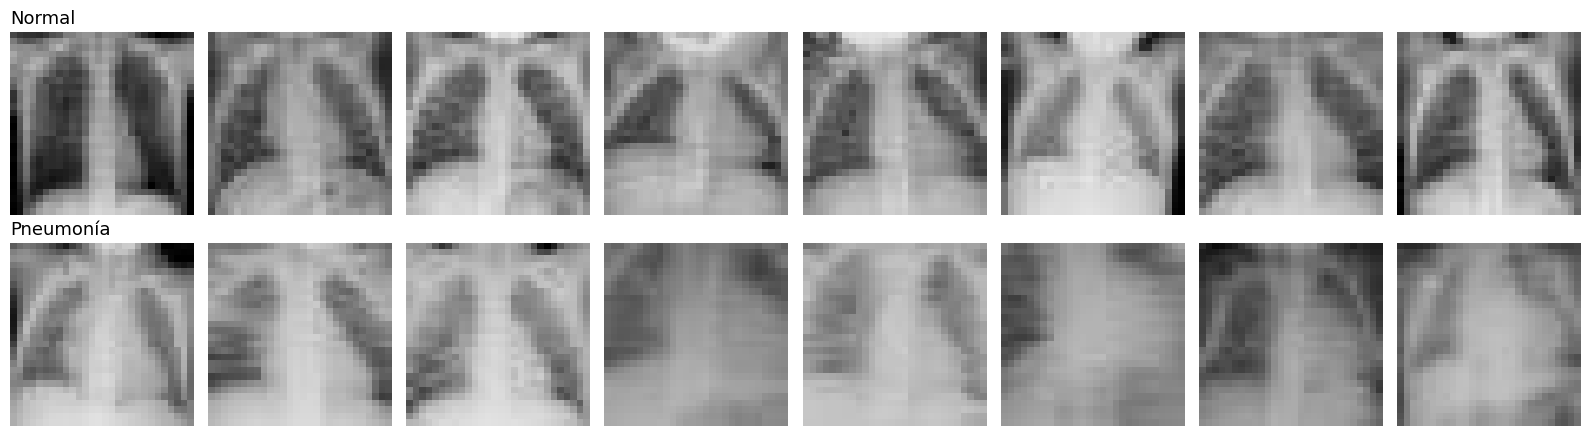

In [4]:
fig, ax = plt.subplots(2, 8, figsize=(16, 4.5))
for fila, clase in enumerate([0, 1]):
    idx = np.where(y_tr.numpy() == clase)[0][:8]
    for a, i in zip(ax[fila], idx):
        a.imshow(x_tr[i, 0], cmap="gray", vmin=0, vmax=1); a.axis("off")
    ax[fila, 0].set_title(["Normal", "Pneumonía"][clase], loc="left", fontsize=13)
plt.tight_layout(); plt.show()

### O modelo «tonto» que sempre di pneumonía

Se sempre respondemos «pneumonía», acertamos o **62.5 %** do test (e o 74 % do adestramento). Calquera modelo
ten que superar ese listón, e mesmo así a accuracy non conta a historia completa.

## 2. Métricas médicas

Con **TP, TN, FP, FN** (positivo = pneumonía):

- **Sensibilidade** (*recall*) $=\dfrac{TP}{TP+FN}$: dos enfermos, a cantos detectamos.
- **Especificidade** $=\dfrac{TN}{TN+FP}$: dos sans, a cantos descartamos ben.
- **AUC-ROC**: capacidade de separar as clases **para todos os limiares á vez** (0.5 = azar, 1 = perfecto).

Un cribado quere sensibilidade alta; unha confirmación quere especificidade alta. **O limiar é unha decisión clínica.**

In [5]:
@torch.no_grad()
def probas(modelo, x, bs=1024):
    modelo.eval()
    return torch.cat([torch.sigmoid(modelo(x[i:i+bs].to(device))).squeeze(1).cpu() for i in range(0, len(x), bs)])

def metricas(p, y, limiar=0.5):
    pred = (p >= limiar).numpy().astype(int); y = y.numpy().astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"accuracy": float((tp + tn) / len(y)), "sensibilidade": float(tp / (tp + fn)), "especificidade": float(tn / (tn + fp)),
            "auc": float(roc_auc_score(y, p.numpy()))}

trivial = metricas(torch.ones(len(y_te)), y_te)
print("Modelo trivial (sempre pneumonía) no test:", {k: round(v, 3) for k, v in trivial.items()})

Modelo trivial (sempre pneumonía) no test: {'accuracy': 0.625, 'sensibilidade': 1.0, 'especificidade': 0.0, 'auc': 0.5}


## 3. Adestramento

O bucle é o mesmo que en MNIST, con dous cambios:

- **Perda BCE** (entropía cruzada binaria): unha única saída (un *logit*) en vez de 10.
- Despois de cada **época** avaliamos na **validación** e gardamos o modelo coa **mellor AUC de validación**
  (*early stopping* a posteriori). Así non “facemos trampa” mirando o test.

`aumento` activa voltas horizontais, pequenos desprazamentos e cambios de contraste ao azar, só ao adestrar.

In [6]:
def aumentar(x):
    '''Aumento de datos barato en GPU: volta horizontal, desprazamento ±2 px e brillo/contraste aleatorio.'''
    n = x.shape[0]
    flip = torch.rand(n, device=x.device) < 0.5
    x = torch.where(flip.view(-1, 1, 1, 1), x.flip(3), x)
    dx, dy = np.random.randint(-2, 3, size=2)
    x = torch.roll(x, shifts=(int(dy), int(dx)), dims=(2, 3))
    a = 1 + 0.2 * (torch.rand(n, 1, 1, 1, device=x.device) - 0.5) * 2        # contraste ±20 %
    b = 0.1 * (torch.rand(n, 1, 1, 1, device=x.device) - 0.5) * 2            # brillo ±0.1
    return (x * a + b).clamp(0, 1)


def adestrar(modelo, epocas=15, lr=1e-3, bs=64, aumento=False, pos_weight=None, nome="modelo"):
    modelo.to(device)
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    pw = None if pos_weight is None else torch.tensor(pos_weight, device=device)
    X, Y = x_tr.to(device), y_tr.to(device)
    hist = {"perda": [], "auc_val": [], "acc_val": []}
    mellor, mellor_auc, t0 = None, -1, time.time()

    for ep in range(1, epocas + 1):
        modelo.train()
        perm = torch.randperm(len(X), device=device)
        suma = 0.0
        for i in range(0, len(X), bs):
            idx = perm[i:i + bs]
            xb, yb = X[idx], Y[idx]
            if aumento: xb = aumentar(xb)
            perda = F.binary_cross_entropy_with_logits(modelo(xb).squeeze(1), yb, pos_weight=pw)
            opt.zero_grad(); perda.backward(); opt.step()
            suma += perda.item() * len(idx)
        m = metricas(probas(modelo, x_va), y_va)
        hist["perda"].append(suma / len(X)); hist["auc_val"].append(m["auc"]); hist["acc_val"].append(m["accuracy"])
        if m["auc"] > mellor_auc:
            mellor_auc, mellor = m["auc"], copy.deepcopy(modelo.state_dict())
        if ep % 5 == 0 or ep == 1:
            print(f"[{nome}] época {ep:2d} | perda {hist['perda'][-1]:.3f} | AUC val {m['auc']:.3f} | acc val {m['accuracy']:.3f}")
    modelo.load_state_dict(mellor)
    print(f"[{nome}] mellor AUC de validación: {mellor_auc:.3f}  ({time.time()-t0:.0f}s)")
    return hist

### Modelo 1 — MLP

Aplanamos a imaxe (784 píxeles) e usamos capas totalmente conectadas: sen noción de veciñanza espacial.

In [7]:
torch.manual_seed(0)
mlp = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 1))
print("Parámetros MLP:", sum(p.numel() for p in mlp.parameters()))
h_mlp = adestrar(mlp, nome="MLP")

Parámetros MLP: 108801
[MLP] época  1 | perda 0.385 | AUC val 0.965 | acc val 0.885
[MLP] época  5 | perda 0.149 | AUC val 0.985 | acc val 0.954
[MLP] época 10 | perda 0.140 | AUC val 0.987 | acc val 0.954
[MLP] época 15 | perda 0.122 | AUC val 0.988 | acc val 0.950
[MLP] mellor AUC de validación: 0.988  (2s)


### Modelo 2 — CNN

Tres bloques convolución → BatchNorm → ReLU → pooling, e unha capa final. **BatchNorm** normaliza as
activacións e estabiliza o adestramento; **Dropout** apaga neuronas ao azar para reducir o sobreaxuste.

In [8]:
def crear_cnn():
    def bloque(i, o):
        return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
    return nn.Sequential(bloque(1, 16), bloque(16, 32), bloque(32, 64),          # 28 -> 14 -> 7 -> 3
                         nn.Flatten(), nn.Dropout(0.3), nn.Linear(64 * 3 * 3, 1))

torch.manual_seed(0)
cnn = crear_cnn()
print("Parámetros CNN:", sum(p.numel() for p in cnn.parameters()))
h_cnn = adestrar(cnn, nome="CNN")

Parámetros CNN: 23985
[CNN] época  1 | perda 0.171 | AUC val 0.989 | acc val 0.945
[CNN] época  5 | perda 0.066 | AUC val 0.997 | acc val 0.968
[CNN] época 10 | perda 0.037 | AUC val 0.996 | acc val 0.968
[CNN] época 15 | perda 0.019 | AUC val 0.995 | acc val 0.968
[CNN] mellor AUC de validación: 0.997  (38s)


### Modelo 3 — A mesma CNN, con aumento de datos e perda ponderada

- **Aumento de datos**: mostramos versións lixeiramente alteradas das imaxes; a rede non pode memorizar.
- **`pos_weight`**: pesa máis os erros da clase minoritaria (normal) para compensar o desequilibrio.
  Aquí poñemos `pos_weight = n_normais / n_pneumonía ≈ 0.35` (resta peso á clase maioritaria).

In [9]:
torch.manual_seed(0)
pw = ((y_tr == 0).sum() / (y_tr == 1).sum()).item()
print(f"pos_weight = {pw:.2f}")
cnn_aug = crear_cnn()
h_aug = adestrar(cnn_aug, aumento=True, pos_weight=pw, nome="CNN+aug")

pos_weight = 0.35
[CNN+aug] época  1 | perda 0.164 | AUC val 0.978 | acc val 0.929
[CNN+aug] época  5 | perda 0.084 | AUC val 0.993 | acc val 0.947
[CNN+aug] época 10 | perda 0.064 | AUC val 0.996 | acc val 0.958
[CNN+aug] época 15 | perda 0.061 | AUC val 0.995 | acc val 0.962
[CNN+aug] mellor AUC de validación: 0.996  (37s)


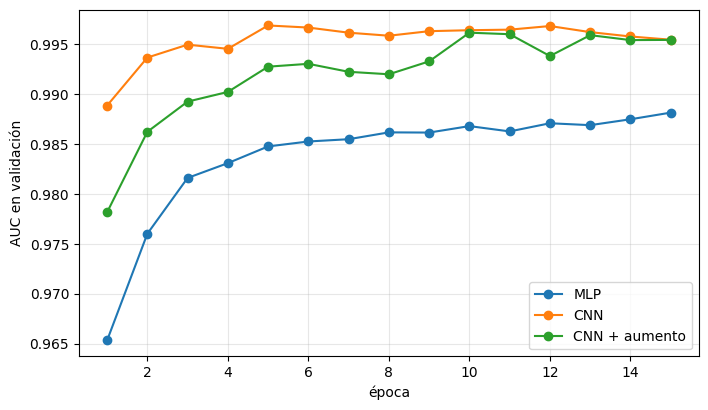

In [10]:
plt.figure(figsize=(8, 4.5))
for h, n in [(h_mlp, "MLP"), (h_cnn, "CNN"), (h_aug, "CNN + aumento")]:
    plt.plot(range(1, len(h["auc_val"]) + 1), h["auc_val"], "o-", label=n)
plt.xlabel("época"); plt.ylabel("AUC en validación"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## 4. Resultados no test

Agora si abrimos o test (unha soa vez). Limiar fixo en 0.5 por agora.

In [11]:
modelos = {"MLP": mlp, "CNN": cnn, "CNN + aumento": cnn_aug}
P = {n: probas(m, x_te) for n, m in modelos.items()}

print(f"{'modelo':16s} {'accuracy':>9s} {'sensib.':>8s} {'especif.':>9s} {'AUC':>6s}")
print(f"{'trivial':16s} {trivial['accuracy']:9.3f} {trivial['sensibilidade']:8.3f} {trivial['especificidade']:9.3f} {trivial['auc']:6.3f}")
for n, p in P.items():
    m = metricas(p, y_te)
    print(f"{n:16s} {m['accuracy']:9.3f} {m['sensibilidade']:8.3f} {m['especificidade']:9.3f} {m['auc']:6.3f}")

modelo            accuracy  sensib.  especif.    AUC
trivial              0.625    1.000     0.000  0.500
MLP                  0.849    0.972     0.645  0.915
CNN                  0.829    0.997     0.547  0.960
CNN + aumento        0.904    0.969     0.795  0.963


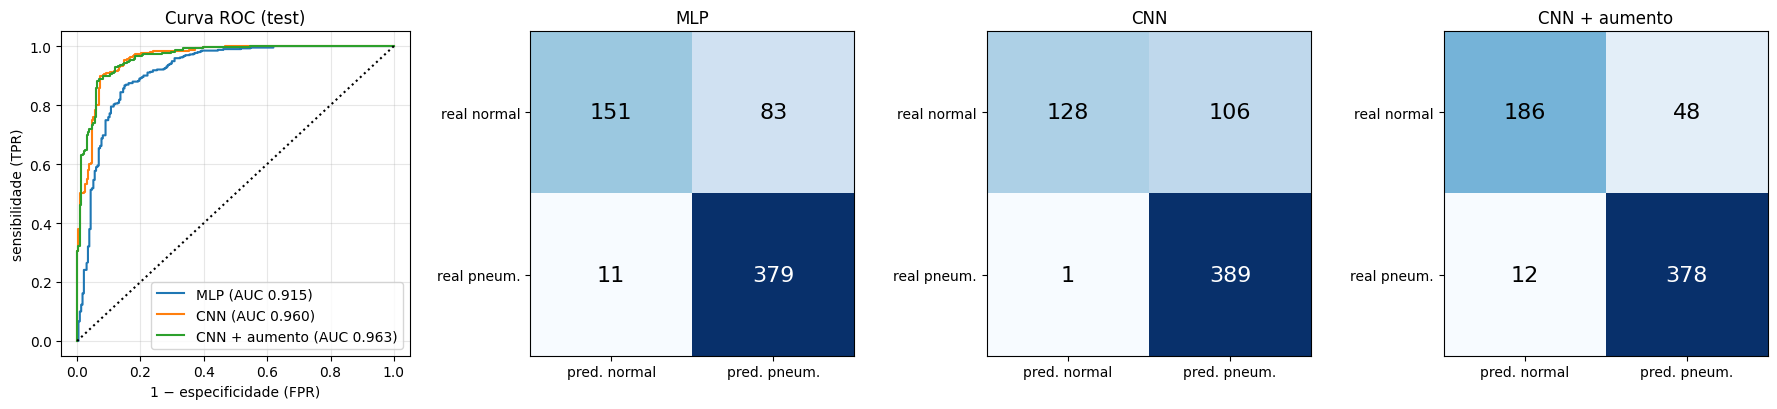

In [12]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4.2))
for n, p in P.items():
    fpr, tpr, _ = roc_curve(y_te.numpy(), p.numpy())
    ax[0].plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(y_te.numpy(), p.numpy()):.3f})")
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_xlabel("1 − especificidade (FPR)"); ax[0].set_ylabel("sensibilidade (TPR)")
ax[0].set_title("Curva ROC (test)"); ax[0].legend(loc="lower right"); ax[0].grid(alpha=0.3)

for a, (n, p) in zip(ax[1:], P.items()):
    cm = confusion_matrix(y_te.numpy().astype(int), (p >= 0.5).numpy().astype(int))
    a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            a.text(j, i, cm[i, j], ha="center", va="center", fontsize=16, color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xticks([0, 1]); a.set_xticklabels(["pred. normal", "pred. pneum."]); a.set_yticks([0, 1]); a.set_yticklabels(["real normal", "real pneum."])
    a.set_title(n)
plt.tight_layout(); plt.show()

Observa a **matriz de confusión**: os dous tipos de erro non custan o mesmo.

- **Falso negativo (FN)**: un caso con pneumonía enviado a casa.
- **Falso positivo (FP)**: un caso san tratado ou observado de máis.

## 5. Escoller o limiar (sobre a validación!)

O limiar 0.5 é unha convención, non unha verdade. Imaxinemos un cribado onde queremos **sensibilidade ≥ 95 %**.
Buscamos **na validación** o limiar máis alto que o consiga, e despois **aplicámolo ao test**.

Escoller o limiar no test sería tramposo: estariamos axustando o modelo ás mesmas imaxes coas que o medimos.

In [13]:
modelo_final = cnn_aug
p_va = probas(modelo_final, x_va)

obxectivo = 0.95
limiares = np.linspace(0.01, 0.99, 99)
validos = [t for t in limiares if metricas(p_va, y_va, t)["sensibilidade"] >= obxectivo]
t_star = max(validos) if validos else 0.5
print(f"Limiar escollido na validación: {t_star:.2f}")

for nome, p, y in [("validación", p_va, y_va), ("test", probas(modelo_final, x_te), y_te)]:
    for t in [0.5, t_star]:
        m = metricas(p, y, t)
        print(f"{nome:11s} limiar {t:.2f} | sensib. {m['sensibilidade']:.3f} | especif. {m['especificidade']:.3f} | acc {m['accuracy']:.3f}")

Limiar escollido na validación: 0.43
validación  limiar 0.50 | sensib. 0.943 | especif. 1.000 | acc 0.958
validación  limiar 0.43 | sensib. 0.954 | especif. 0.993 | acc 0.964
test        limiar 0.50 | sensib. 0.969 | especif. 0.795 | acc 0.904
test        limiar 0.43 | sensib. 0.974 | especif. 0.756 | acc 0.893


Dúas lecións:

1. Subir a sensibilidade **custa especificidade**.
2. Compara **validación e test**: na validación a especificidade é case perfecta, e no test cae moito. O test
   ten outra proporción de clases e outros casos (o limiar escollido na validación non “viaxa” ben). É un
   **cambio de dominio** en miniatura, e o motivo de reservar un test e de desconfiar de calquera número que
   non veña de datos independentes.

## 6. Onde mira a rede? (mapa de saliencia)

Un modelo médico que acerta pola razón equivocada (un marcador, o bordo da imaxe, a etiqueta do hospital) é
perigoso. O **mapa de saliencia** mide canto cambiaría a predición se modificásemos cada píxel:
é o gradiente da saída respecto da entrada, $|\partial\,\text{logit}/\partial x|$.

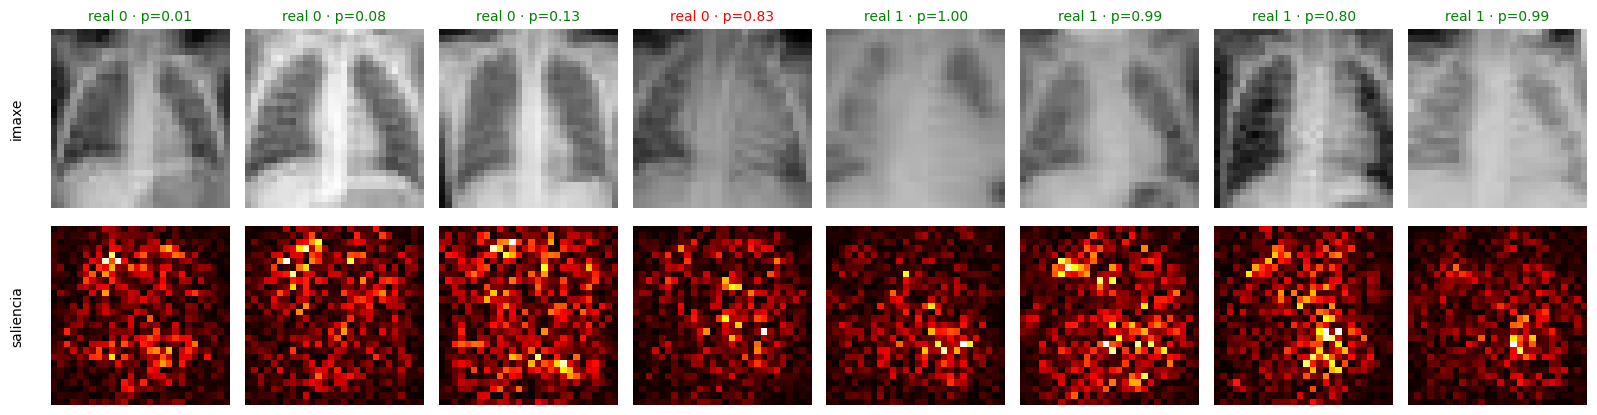

In [14]:
def saliencia(modelo, x):
    modelo.eval()
    x = x.clone().unsqueeze(0).to(device).requires_grad_(True)
    modelo(x).squeeze().backward()
    return x.grad.abs()[0, 0].cpu()

p_te = probas(modelo_final, x_te)
rng = np.random.RandomState(1)
idx = np.concatenate([rng.choice(np.where(y_te.numpy() == c)[0], 4, replace=False) for c in (0, 1)])

fig, ax = plt.subplots(2, 8, figsize=(16, 4.4))
for k, i in enumerate(idx):
    ax[0, k].imshow(x_te[i, 0], cmap="gray", vmin=0, vmax=1)
    ok = (p_te[i] >= 0.5).item() == bool(y_te[i].item())
    ax[0, k].set_title(f"real {int(y_te[i])} · p={p_te[i]:.2f}", color="green" if ok else "red", fontsize=10)
    ax[1, k].imshow(saliencia(modelo_final, x_te[i]), cmap="hot")
    ax[0, k].axis("off"); ax[1, k].axis("off")
ax[0, 0].text(-0.15, 0.5, "imaxe", transform=ax[0, 0].transAxes, rotation=90, va="center", ha="right")
ax[1, 0].text(-0.15, 0.5, "saliencia", transform=ax[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout(); plt.show()

**Para discutir:** a saliencia sinala os pulmóns ou o bordo e o exterior? Unha saliencia sobre o fondo
sería sinal de **atallo** (*shortcut learning*), un problema clásico en radioloxía con IA.

## 7. Resumo e ideas para probar

- Cunha CNN diminuta e poucos segundos de adestramento xa se supera con folgura ao modelo trivial.
- **Accuracy non abonda**: reporta sensibilidade, especificidade e AUC.
- O **limiar** escóllese na validación, segundo o uso clínico.
- Os resultados na validación eran moito mellores ca no test: mini-exemplo de **cambio de dominio**.

**Para probar:**

1. Quita o aumento de datos (`aumento=False`) mantendo `pos_weight`, e viceversa. Que axuda máis?
2. Cambia a resolución: MedMNIST ten tamaños 64, 128 e 224 (`pneumoniamnist_64.npz`). Vale a pena o custo?
3. Aumenta `epocas` a 50. Sobreaxusta? Mira a curva de AUC de validación.
4. Proba outros conxuntos MedMNIST (`dermamnist`, `bloodmnist`): cambia a URL e a saída a `n_clases`.
5. Repite o adestramento con `torch.manual_seed(1), (2), (3)`: canto varía o resultado? Esa é a incerteza real.